<center>
  <h3>More than a Hack 2027 &middot; Phase 1</h3>
  <h2>Frame-level Ball Possession (Exploratory Data Analysis)</h2>

  <p><strong>Metrica Sports &times; FC Barcelona Innovation Hub &times; Mobile World Capital</strong></p>
</center>

---

### Carried By Admin Team - Sepuluh Nopember Institute of Technology - Indonesia

- **Rasya Arya Ramadhan**
- **Benedictus Ryu Gunawan**
- **Ahmad Naufal Farras**
- **Jeremy Mattathis Mboe**
- **Jylan Annisa Mumtaza Syidana**

---

## Ringkasan

Task ini meminta satu label untuk **setiap frame** (199.319 frame, 25 fps) pada satu pertandingan penuh FC Barcelona vs Athletic Club: `H` (tuan rumah menguasai bola), `A` (tamu menguasai bola), `D` (bola mati), atau `X` (abstain). Input berupa dua video, tracking otomatis (ATD) beserta bola, Smart Tagging, dan homografi.

Notebook ini hanya **memahami data**. Fokusnya: blok frame yang dinilai, seberapa sering dan di mana bola hilang dari tracking, kualitas track pemain (fragmentasi dan loncatan identitas), sinyal geometri bola-pemain yang bisa dipakai state model, serta isi dan keandalan Smart Tagging. Ground truth publik hanya dipakai untuk memeriksa kebenaran pipeline dan **tidak** dipakai untuk tuning (lihat `RULES.md`).

Metrik peringkat adalah **spellF1**: possession dicocokkan satu-satu dengan kebenaran lewat IoU temporal, lalu F1 dirata-ratakan pada ambang 0,3 sampai 0,7.

$$
\mathrm{IoU}(p, g) = \frac{|p \cap g|}{|p \cup g|},
\qquad
\mathrm{spellF1} = \frac{1}{5}\sum_{\tau \in \{0.3,\,0.4,\,0.5,\,0.6,\,0.7\}} F1_\tau
$$


# Metodologi

Alur EDA dibangun dari data mentah ke sinyal yang berguna untuk model:

**Aset → blok frame dinilai → visibilitas bola → kualitas track → geometri bola-pemain → bentuk tim → Smart Tagging → korelasi fitur → ringkasan.**

Semua gambar memakai satu palet: `#e94f37` (merah-oranye, tuan rumah / sinyal utama), `#393e41` (arang, tamu / sinyal sekunder / teks), dan `#f6f7eb` (latar). Merah-oranye dan arang berbeda jauh dalam kecerahan sehingga tetap terbaca pada skala abu-abu. Gambar tidak memakai garis grid, dan legenda diletakkan di luar area plot agar tidak menimpa data.

# Environment

Notebook dijalankan dari dalam repositori. Seluruh path berasal dari `games.asset_paths()`, sehingga tidak ada nama berkas yang ditulis manual. Data pertandingan **tidak** disalin ke repositori (lihat `.gitignore`). Parsing ATD penuh di-cache di `experiments/_cache/`.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "games.py").exists())
for p in (ROOT, ROOT / "starter", ROOT / "evaluation", ROOT / "experiments"):
    sys.path.insert(0, str(p))

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd
from IPython.display import display

import common
from games import asset_paths, half_video_blocks, source_frames

# --- palet ---------------------------------------------------------------------------
C1, C2, C3 = "#e94f37", "#393e41", "#f6f7eb"     # merah-oranye (utama/tuan rumah), arang (sekunder/tamu), latar
INK, GREY, WARM = "#393e41", "#a3a7a6", "#393e41"   # WARM = garis ambang (arang)
CMAP = LinearSegmentedColormap.from_list("sunset", [C3, C1, C2])
CMAP_DIV = LinearSegmentedColormap.from_list("div", [C2, "#ffffff", C1])
TEAM = {"H": C1, "A": C2, "D": GREY, "X": "#dcdcd0"}

mpl.rcParams.update({
    "figure.facecolor": C3, "savefig.facecolor": C3, "axes.facecolor": "white",
    "axes.edgecolor": INK, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.titleweight": "bold",
    "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "font.family": "sans-serif",
    "legend.frameon": False, "legend.fontsize": 8, "figure.dpi": 110,
    "axes.prop_cycle": mpl.cycler(color=[C1, C2, GREY, WARM]),
})

def panel(ax, letter):
    ax.text(-0.09, 1.07, letter, transform=ax.transAxes, fontsize=12, fontweight="bold", va="top")

def pitch(ax, lw=0.8, col=INK, alpha=0.55):
    """Lapangan 105,3 x 68 m, asal di pojok, tanpa grid."""
    L, W = 105.3, 68.0
    kw = dict(color=col, lw=lw, alpha=alpha)
    ax.plot([0, L, L, 0, 0], [0, 0, W, W, 0], **kw); ax.plot([L / 2] * 2, [0, W], **kw)
    ax.add_patch(plt.Circle((L / 2, W / 2), 9.15, fill=False, **kw))
    for x0, s in ((0, 1), (L, -1)):
        ax.plot([x0, x0 + s * 16.5, x0 + s * 16.5, x0], [W / 2 - 20.15, W / 2 - 20.15, W / 2 + 20.15, W / 2 + 20.15], **kw)
        ax.plot([x0, x0 + s * 5.5, x0 + s * 5.5, x0], [W / 2 - 9.16, W / 2 - 9.16, W / 2 + 9.16, W / 2 + 9.16], **kw)
    ax.set(xlim=(0, L), ylim=(W, 0), aspect="equal", xticks=[], yticks=[]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)

FPS = 25
LEN, WID = 105.3, 68.0
N = source_frames("tactical")
BLOCKS = half_video_blocks("BAR-ATH")
GRADED = np.zeros(N, bool)
for _, a, b in BLOCKS:
    GRADED[a:b + 1] = True
MIN = np.arange(N) / FPS / 60
print("ROOT:", ROOT, "| frames:", N, "| graded:", GRADED.sum())

ROOT: /home/ryz/data/dev/competitive/hackathon/More Than hack/more-than-a-hack-2027 | frames: 199319 | graded: 158857


# Dataset

## [1] Aset yang tersedia

`tactical` adalah referensi evaluasi: baris ke-*i* pada submission adalah frame ke-*i* video ini. `broadcast` bersifat opsional dan **tidak tersinkron**.

In [2]:
rows = []
for src in ("tactical", "broadcast"):
    for name, path in asset_paths(source=src).items():
        path = Path(path)
        rows.append({"source": src, "asset": name, "ada": path.exists(),
                     "MB": round(path.stat().st_size / 1e6, 1) if path.exists() else None})
display(pd.DataFrame(rows))

,source,asset,ada,MB
0,tactical,video,True,5222.3
1,tactical,atd_meta,True,0.1
2,tactical,atd_raw,True,195.7
3,tactical,homography,False,NaN
4,tactical,smart_tagging,True,0.3
5,broadcast,video,False,NaN
6,broadcast,atd_meta,True,0.1
7,broadcast,atd_raw,True,142.0
8,broadcast,homography,True,15.4


Berkas dengan `ada = False` perlu diunduh ulang sebelum dipakai (homografi tactical dan video broadcast belum ada di folder `data/`). Seluruh EDA di bawah hanya memakai berkas yang sudah tersedia.

## [2] Memuat ATD

ATD disimpan sebagai tiga larik: posisi dan kecepatan 46 slot track (`P`), bola (`B`), dan tim tiap slot (`T`, 0 = tuan rumah). Koordinat ternormalisasi 0 sampai 1, lalu dikonversi ke meter karena lapangan tidak persegi.

In [3]:
P, B, T = common.load_atd_arrays()             # P (N,46,3) x,y,speed | B (N,3) | T (46,) 0=H 1=A
PX, PY = P[..., 0] * LEN, P[..., 1] * WID       # meter
BX, BY = B[:, 0] * LEN, B[:, 1] * WID
BALL = np.isfinite(BX)
PRES = np.isfinite(PX)
NPLAY = PRES.sum(1)
# kecepatan bola dari posisi (kolom speed ATD untuk bola hampir selalu NaN); NaN bila salah satu frame tanpa bola
BSPEED = np.full(N, np.nan)
BSPEED[1:] = np.hypot(np.diff(BX), np.diff(BY)) * FPS
BSPEED[BSPEED > 40] = np.nan                       # >40 m/s = loncatan tracking, bukan bola

print(f"slot home: {int((T == 0).sum())} | slot away: {int((T == 1).sum())}")
print(f"bola terlihat: semua {BALL.mean():.1%} | dinilai {BALL[GRADED].mean():.1%}")
print(f"pemain terlacak per frame dinilai: rata-rata {NPLAY[GRADED].mean():.1f}, maks {NPLAY[GRADED].max()}")

slot home: 24 | slot away: 22
bola terlihat: semua 56.9% | dinilai 59.3%
pemain terlacak per frame dinilai: rata-rata 20.5, maks 25


Jumlah slot (46) hampir dua kali jumlah pemain di lapangan. Slot muncul, hilang, dan bertukar identitas, jadi analisis harus bersifat kolektif per tim, bukan per pemain.

# Exploratory Data Analysis

## [1] Linimasa pertandingan

Empat panel berbagi sumbu waktu: blok yang dinilai, visibilitas bola, jumlah pemain terlacak, dan kecepatan bola. Penyajian per jendela 30 detik meredam derau per frame.

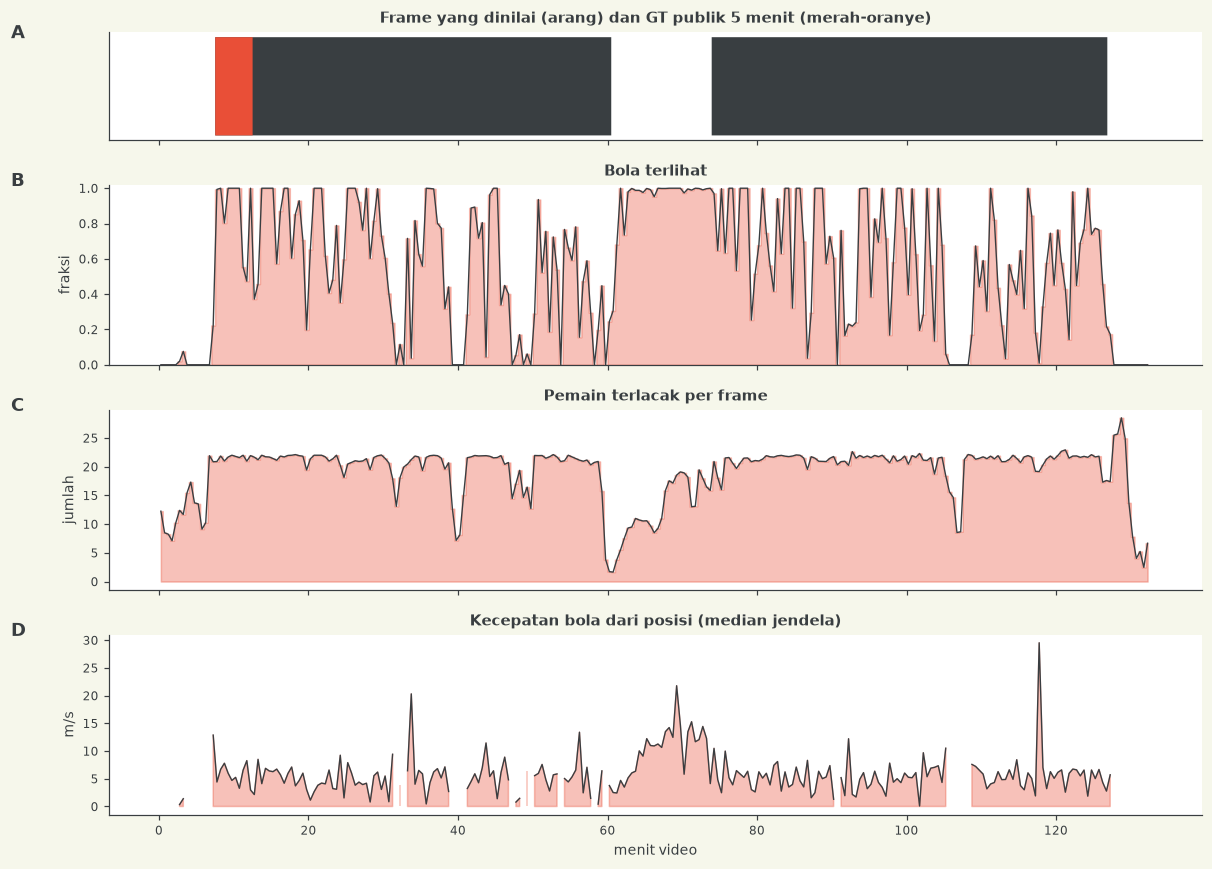

In [4]:
W = 30 * FPS
nwin = N // W
def win(x): return x[:nwin * W].reshape(nwin, W).astype(float)
tw = (np.arange(nwin) * W + W / 2) / FPS / 60

fig, ax = plt.subplots(4, 1, figsize=(11, 8), sharex=True, gridspec_kw=dict(height_ratios=[0.6, 1, 1, 1]))
ax[0].fill_between(MIN, GRADED, step="mid", color=C2, lw=0)
ax[0].fill_between(MIN, GRADED & (np.arange(N) <= 18684), step="mid", color=C1, lw=0)
ax[0].set(yticks=[], title="Frame yang dinilai (arang) dan GT publik 5 menit (merah-oranye)")
ax[1].fill_between(tw, win(BALL).mean(1), color=C1, alpha=0.35, step="mid"); ax[1].plot(tw, win(BALL).mean(1), color=C2, lw=0.9)
ax[1].set(ylim=(0, 1.02), ylabel="fraksi", title="Bola terlihat")
ax[2].fill_between(tw, win(NPLAY).mean(1), color=C1, alpha=0.35, step="mid"); ax[2].plot(tw, win(NPLAY).mean(1), color=C2, lw=0.9)
ax[2].set(ylabel="jumlah", title="Pemain terlacak per frame")
bs = np.nanmedian(win(BSPEED), 1)
ax[3].plot(tw, bs, color=C2, lw=0.9); ax[3].fill_between(tw, bs, color=C1, alpha=0.35)
ax[3].set(ylabel="m/s", xlabel="menit video", title="Kecepatan bola dari posisi (median jendela)")
for a, l in zip(ax, "ABCD"): panel(a, l)
fig.tight_layout(); plt.show()

Visibilitas bola **bimodal**: dalam jendela 30 detik, bola hampir selalu terlihat atau hampir selalu hilang, dengan banyak blok panjang tanpa bola di kedua babak. Jumlah pemain terlacak stabil di sekitar 22 selama permainan, tetapi turun tajam saat turun minum dan awal babak kedua. Kualitas tracking bergantung pada momen permainan, bukan pada waktu.

## [2] Bola hilang: durasi gap

Gap adalah deretan frame berurutan tanpa bola pada frame yang dinilai. Distribusi durasinya menentukan seberapa jauh state sebelumnya boleh dipertahankan.

gap: 150 | median 10.7 dtk | P90 33.8 dtk | maks 221 dtk
gap < 1 dtk: 11.3% | gap > 10 dtk: 52.7% | share frame hilang pada gap > 10 dtk: 85.2%


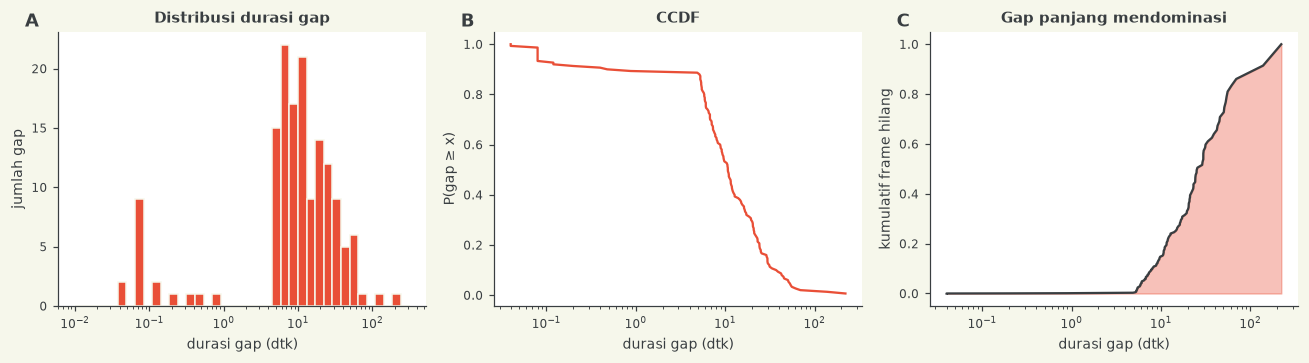

In [5]:
vis = BALL[GRADED]
edges = np.diff(np.concatenate(([1], vis.astype(int), [1])))
starts, ends = np.flatnonzero(edges == -1), np.flatnonzero(edges == 1)
gap = (ends - starts) / FPS
print(f"gap: {len(gap)} | median {np.median(gap):.1f} dtk | P90 {np.percentile(gap, 90):.1f} dtk | maks {gap.max():.0f} dtk")
print(f"gap < 1 dtk: {np.mean(gap < 1):.1%} | gap > 10 dtk: {np.mean(gap > 10):.1%} | share frame hilang pada gap > 10 dtk: {gap[gap > 10].sum() / gap.sum():.1%}")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].hist(gap, bins=np.logspace(-2, 2.5, 40), color=C1, edgecolor=C3)
ax[0].set(xscale="log", xlabel="durasi gap (dtk)", ylabel="jumlah gap", title="Distribusi durasi gap")
g = np.sort(gap)[::-1]; ax[1].plot(g, np.arange(1, len(g) + 1) / len(g), color=C1)
ax[1].set(xscale="log", xlabel="durasi gap (dtk)", ylabel="P(gap ≥ x)", title="CCDF")
cum = np.cumsum(np.sort(gap)) / gap.sum()
ax[2].plot(np.sort(gap), cum, color=C2); ax[2].fill_between(np.sort(gap), cum, color=C1, alpha=0.35)
ax[2].set(xscale="log", xlabel="durasi gap (dtk)", ylabel="kumulatif frame hilang", title="Gap panjang mendominasi")
for a, l in zip(ax, "ABC"): panel(a, l)
fig.tight_layout(); plt.show()

Gap umumnya **panjang**: hanya sekitar 11% yang kurang dari 1 detik, median 10,7 detik, dan 85% dari seluruh frame tanpa bola berasal dari gap lebih dari 10 detik (panel C). Menahan state sebelumnya tidak aman untuk gap sepanjang itu: di dalamnya hampir pasti terjadi bola mati atau pergantian possession. Gap panjang menuntut sumber informasi lain (posisi pemain, Smart Tagging, atau bola dari video), bukan sekadar interpolasi.

## [3] Di mana bola hilang

Panel A memetakan posisi terakhir yang diketahui sebelum gap dimulai. Panel B memetakan peluang bola hilang satu detik kemudian, dihitung per sel lapangan dari frame yang bolanya terlihat.

P(bola hilang 1 dtk kemudian | terlihat) = 3.6%


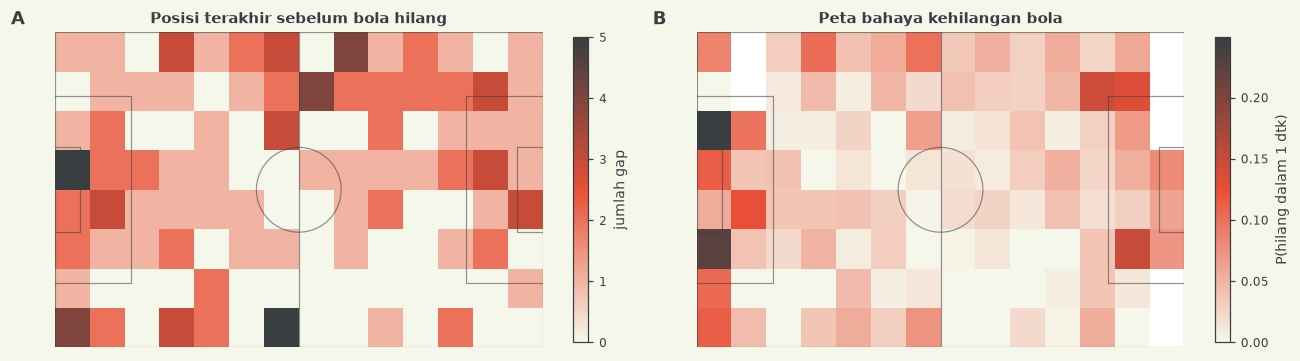

In [6]:
gidx = np.flatnonzero(GRADED)
last = gidx[starts[starts > 0] - 1]                       # frame terakhir bola terlihat sebelum gap
lx, ly = BX[last], BY[last]

vis_i = np.flatnonzero(GRADED & BALL)
vis_i = vis_i[vis_i + FPS < N]
lost = ~BALL[vis_i + FPS]
bins = (np.linspace(0, LEN, 15), np.linspace(0, WID, 9))
num, _, _ = np.histogram2d(BX[vis_i][lost], BY[vis_i][lost], bins=bins)
den, _, _ = np.histogram2d(BX[vis_i], BY[vis_i], bins=bins)
haz = np.where(den > 200, num / np.maximum(den, 1), np.nan)
print(f"P(bola hilang 1 dtk kemudian | terlihat) = {lost.mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
h = ax[0].hist2d(lx, ly, bins=bins, cmap=CMAP)[3]; plt.colorbar(h, ax=ax[0], shrink=0.75, label="jumlah gap")
pitch(ax[0]); ax[0].set_title("Posisi terakhir sebelum bola hilang")
m = ax[1].pcolormesh(bins[0], bins[1], haz.T, cmap=CMAP, vmin=0); plt.colorbar(m, ax=ax[1], shrink=0.75, label="P(hilang dalam 1 dtk)")
pitch(ax[1]); ax[1].set_title("Peta bahaya kehilangan bola")
panel(ax[0], "A"); panel(ax[1], "B"); fig.tight_layout(); plt.show()

Peluang bola hilang dalam satu detik hanya 3,6% secara rata-rata, jadi kehilangan bukan derau per frame: begitu bola hilang, ia cenderung hilang lama (konsisten dengan gap panjang). Peta A dan B menunjukkan zona tempat kehilangan terkonsentrasi. Model sebaiknya memperlakukan "bola hilang" sebagai keadaan yang berdurasi.

## [4] Kualitas track pemain

Tiga pemeriksaan: jumlah pemain terlacak, panjang tracklet per slot, dan loncatan posisi yang mustahil (lebih dari 2 m dalam 1/25 detik, yaitu di atas 50 m/s) sebagai penanda pertukaran identitas.

tracklet: 2218 | median 13.6 dtk | P90 201 dtk | maks 2937 dtk
loncatan > 2 m: 83 pada frame dinilai (0.52 per 1000 frame)


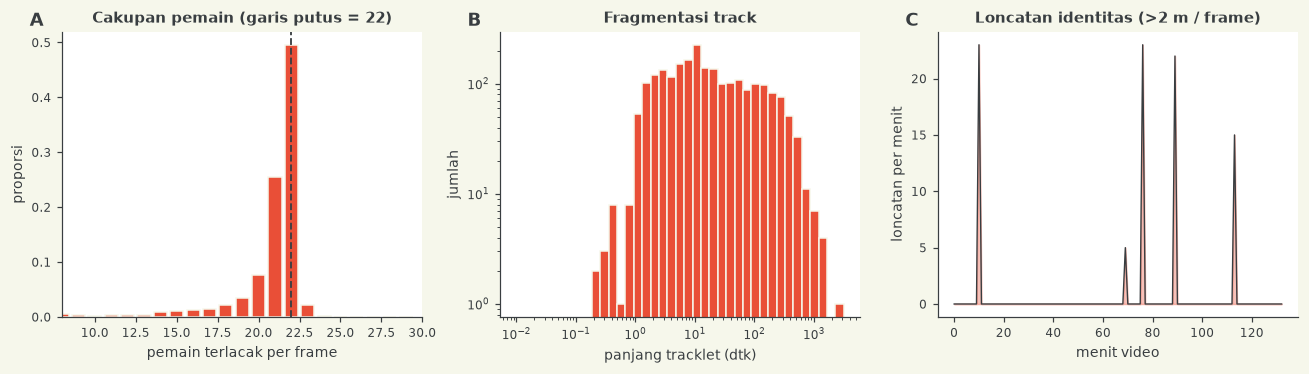

In [7]:
# panjang tracklet: deret frame berurutan sebuah slot hadir
tl = []
for s in range(46):
    e = np.diff(np.concatenate(([0], PRES[:, s].astype(int), [0])))
    tl.extend((np.flatnonzero(e == -1) - np.flatnonzero(e == 1)) / FPS)
tl = np.array(tl)

# loncatan: slot hadir di dua frame berurutan tapi bergeser > 2 m
d = np.hypot(np.diff(PX, axis=0), np.diff(PY, axis=0))
jump = np.nan_to_num(d) > 2.0
jump_min = pd.Series(jump.sum(1)).groupby(np.arange(N - 1) // (FPS * 60)).sum()
print(f"tracklet: {len(tl)} | median {np.median(tl):.1f} dtk | P90 {np.percentile(tl, 90):.0f} dtk | maks {tl.max():.0f} dtk")
print(f"loncatan > 2 m: {int(jump[GRADED[:-1]].sum())} pada frame dinilai ({jump[GRADED[:-1]].sum() / GRADED.sum() * 1000:.2f} per 1000 frame)")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
cnt = np.bincount(NPLAY[GRADED], minlength=30)[:30]
ax[0].bar(np.arange(30), cnt / cnt.sum(), color=C1, edgecolor=C3)
ax[0].axvline(22, color=WARM, lw=1.2, ls="--")
ax[0].set(xlabel="pemain terlacak per frame", ylabel="proporsi", title="Cakupan pemain (garis putus = 22)", xlim=(8, 30))
ax[1].hist(tl, bins=np.logspace(-2, 3.5, 40), color=C1, edgecolor=C3)
ax[1].set(xscale="log", yscale="log", xlabel="panjang tracklet (dtk)", ylabel="jumlah", title="Fragmentasi track")
ax[2].plot(jump_min.index, jump_min.values, color=C2, lw=0.9); ax[2].fill_between(jump_min.index, jump_min.values, color=C1, alpha=0.35)
ax[2].set(xlabel="menit video", ylabel="loncatan per menit", title="Loncatan identitas (>2 m / frame)")
for a, l in zip(ax, "ABC"): panel(a, l)
fig.tight_layout(); plt.show()

Cakupan pemain rata-rata 20,5 (maksimum 25, karena duplikat). Tracklet bermedian 13,6 detik tetapi sangat heterogen (P90 sekitar 200 detik): sebagian slot stabil, sebagian terfragmentasi. Loncatan mustahil jarang (sekitar 0,5 per 1000 frame), tetapi slot tetap bukan pemain. Fitur kolektif per tim (jarak tim terdekat ke bola) lebih aman daripada fitur per pemain.

## [5] Geometri bola-pemain

Fitur dasar yang sudah dipakai baseline: jarak ke pemain terdekat dari masing-masing tim. Selisih jarak (*margin*) mengukur ambiguitas kontes bola: margin kecil berarti kedua tim sama-sama dekat.

frame dengan bola dan >=1 pemain tiap tim: 99.8%
jarak terdekat  median 1.9 m | P90 7.0 m
margin          median 3.5 m | margin < 2 m: 32.5%


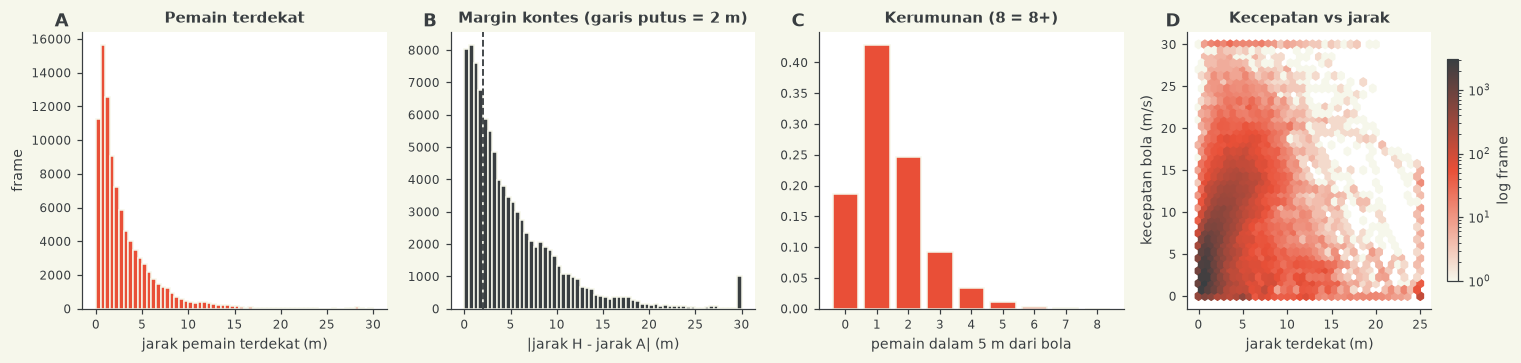

In [8]:
idx = np.flatnonzero(GRADED & BALL)
dx = PX[idx] - BX[idx, None]; dy = PY[idx] - BY[idx, None]
D = np.hypot(dx, dy)
D[~PRES[idx]] = np.inf
dh = np.where(T[None] == 0, D, np.inf).min(1)
da = np.where(T[None] == 1, D, np.inf).min(1)
near = np.minimum(dh, da)
margin = np.abs(dh - da)
within5 = (D < 5).sum(1)
ball_speed = BSPEED[idx]
ok = np.isfinite(near) & np.isfinite(margin)
print(f"frame dengan bola dan >=1 pemain tiap tim: {ok.mean():.1%}")
print(f"jarak terdekat  median {np.median(near[ok]):.1f} m | P90 {np.percentile(near[ok], 90):.1f} m")
print(f"margin          median {np.median(margin[ok]):.1f} m | margin < 2 m: {np.mean(margin[ok] < 2):.1%}")

fig, ax = plt.subplots(1, 4, figsize=(14, 3.4))
ax[0].hist(np.clip(near[ok], 0, 30), bins=60, color=C1, edgecolor=C3); ax[0].set(xlabel="jarak pemain terdekat (m)", ylabel="frame", title="Pemain terdekat")
ax[1].hist(np.clip(margin[ok], 0, 30), bins=60, color=C2, edgecolor=C3); ax[1].axvline(2, color=WARM, ls="--", lw=1.2)
ax[1].set(xlabel="|jarak H - jarak A| (m)", title="Margin kontes (garis putus = 2 m)")
bc = np.bincount(np.clip(within5, 0, 8), minlength=9); ax[2].bar(range(9), bc / bc.sum(), color=C1, edgecolor=C3)
ax[2].set(xlabel="pemain dalam 5 m dari bola", title="Kerumunan (8 = 8+)", xticks=range(9))
hb = ax[3].hexbin(np.clip(near[ok], 0, 25), np.clip(ball_speed[ok], 0, 30), gridsize=35, cmap=CMAP, bins="log", mincnt=1)
plt.colorbar(hb, ax=ax[3], shrink=0.8, label="log frame"); ax[3].set(xlabel="jarak terdekat (m)", ylabel="kecepatan bola (m/s)", title="Kecepatan vs jarak")
for a, l in zip(ax, "ABCD"): panel(a, l)
fig.tight_layout(); plt.show()

Pada frame yang bolanya terlihat, pemain terdekat berjarak sekitar 1,9 m (median) dan 7 m pada P90. Sepertiga frame (32,5%) berselisih kurang dari 2 m antara pemain terdekat kedua tim, yaitu kontes yang ambigu. Di situlah "pemain terdekat" paling mudah salah, sehingga bukti temporal (siapa yang memegang bola sebelumnya) lebih tepat daripada keputusan per frame.

## [6] Bentuk dan arah tim

Posisi tim per babak memperlihatkan arah serang (sisi gawang berganti di babak kedua) dan lebar-panjang formasi sepanjang waktu. Arah serang diperlukan jika kelak memakai fitur seperti "bola di sepertiga akhir".

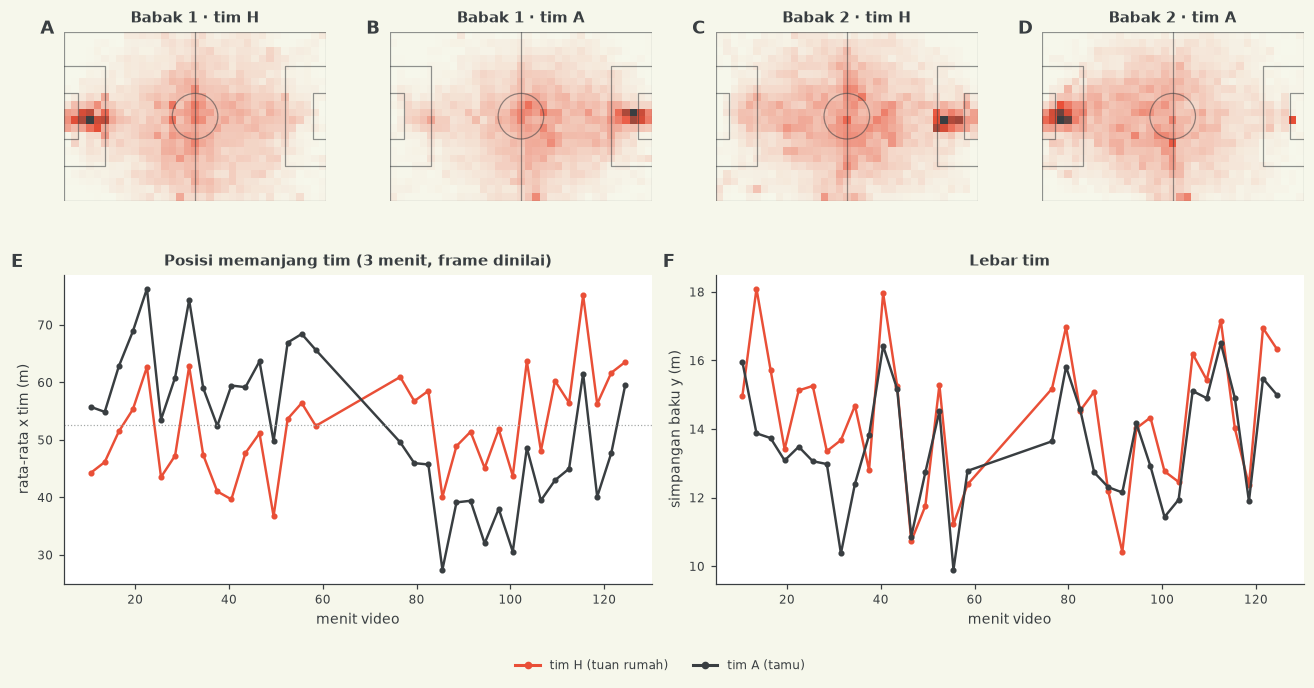

In [9]:
def team_xy(team, a, b):
    m = (T == team)[None] & PRES[a:b + 1]
    return PX[a:b + 1][m], PY[a:b + 1][m]

fig = plt.figure(figsize=(12, 7.2))
gs = fig.add_gridspec(2, 4, height_ratios=[1.35, 1])
cells_ = [(0, 0), (0, 1), (0, 2), (0, 3)]
k = 0
for half, a, b in BLOCKS:
    for team, nm in ((0, "H"), (1, "A")):
        ax = fig.add_subplot(gs[0, k]); k += 1
        x, y = team_xy(team, a, b)
        h = ax.hist2d(x, y, bins=(np.linspace(0, LEN, 36), np.linspace(0, WID, 23)), cmap=CMAP)[3]
        pitch(ax); ax.set_title(f"Babak {half} · tim {nm}")
        panel(ax, "ABCD"[k - 1])

WW = 4500   # 3 menit
starts_w = [s for s in range(0, N - WW, WW) if GRADED[s:s + WW].all()]
tw3 = (np.array(starts_w) + WW / 2) / FPS / 60
def tstat(team, fn, arr):
    return np.array([fn(np.where((T == team)[None] & PRES[s:s + WW], arr[s:s + WW], np.nan)) for s in starts_w])
ax = fig.add_subplot(gs[1, :2])
for team, c, nm in ((0, C1, "H"), (1, C2, "A")):
    ax.plot(tw3, tstat(team, np.nanmean, PX), color=c, lw=1.6, marker="o", ms=3, label=f"tim {nm}")
ax.axhline(LEN / 2, color=GREY, lw=0.8, ls=":")
ax.set(xlabel="menit video", ylabel="rata-rata x tim (m)", title="Posisi memanjang tim (3 menit, frame dinilai)")
panel(ax, "E")
ax = fig.add_subplot(gs[1, 2:])
for team, c, nm in ((0, C1, "H"), (1, C2, "A")):
    ax.plot(tw3, tstat(team, np.nanstd, PY), color=c, lw=1.6, marker="o", ms=3, label=f"tim {nm}")
ax.set(xlabel="menit video", ylabel="simpangan baku y (m)", title="Lebar tim"); panel(ax, "F")
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([0], [0], color=C1, lw=2, marker="o", ms=4, label="tim H (tuan rumah)"), Line2D([0], [0], color=C2, lw=2, marker="o", ms=4, label="tim A (tamu)")],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

Kepadatan tertinggi berada di depan gawang sendiri (kiper), dan sisinya **tertukar** antar babak: tuan rumah menempati gawang kiri di babak 1 dan gawang kanan di babak 2, tamu sebaliknya. Arah serang karena itu harus ditentukan per babak. Posisi rata-rata tim berosilasi mengikuti siapa yang menyerang.

## [7] Smart Tagging

638 fase permainan dan bola mati yang dibuat otomatis. Interval adalah *fase*, bukan possession, dan tag `Team` kadang bernilai `N/A`.

/tmp/ipykernel_64577/462566844.py:26: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ax.set(yticks=range(len(ct)), yticklabels=ct.index, xlabel="jumlah instance", title="Jumlah per kode dan tim", xlim=(0, ct.sum(1).max() * 1.06)); ax.invert_yaxis(); panel(ax, "B")


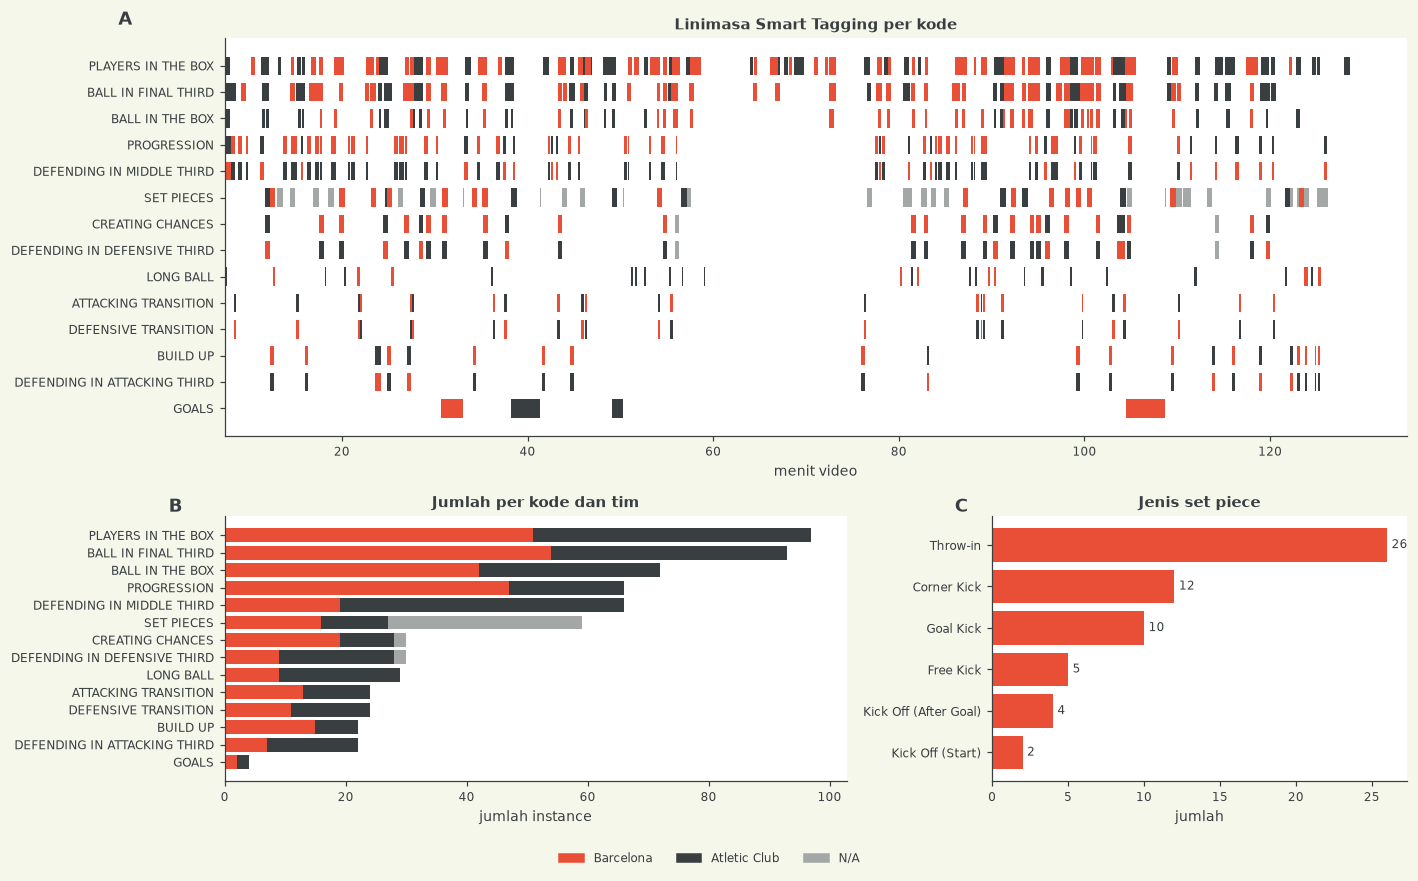

                              count   mean    50%    max
code                                                    
ATTACKING TRANSITION           24.0   15.5   15.4   22.0
BALL IN FINAL THIRD            93.0   30.1   27.0   70.8
BALL IN THE BOX                72.0   18.1   17.4   32.5
BUILD UP                       22.0   20.0   20.5   28.6
CREATING CHANCES               30.0   30.0   30.0   30.0
DEFENDING IN ATTACKING THIRD   22.0   20.0   20.5   28.6
DEFENDING IN DEFENSIVE THIRD   30.0   30.0   30.0   30.0
DEFENDING IN MIDDLE THIRD      66.0   18.9   17.6   37.1
DEFENSIVE TRANSITION           24.0   15.5   15.4   22.0
GOALS                           4.0  165.0  169.3  250.7
LONG BALL                      29.0   13.1   12.4   22.2
PLAYERS IN THE BOX             97.0   35.5   27.7   83.7
PROGRESSION                    66.0   18.9   17.6   37.1
SET PIECES                     59.0   31.9   35.0   35.0

interval yang dibagi dua kode (kembar):
code
(DEFENDING IN MIDDLE THIRD, PROGRESSION)  

In [10]:
from load_smart_tagging import load as load_tags
raw = load_tags()
tags = pd.DataFrame([{**{k: v for k, v in t.items() if k != "tags"}, **t["tags"]} for t in raw])
tags["dur"] = (tags.end_s - tags.start_s)
tags["t_min"] = tags.start_s / 60
order = tags.code.value_counts().index.tolist()
tcol = {"Barcelona": C1, "Atletic Club": C2, "N/A": GREY}

fig = plt.figure(figsize=(13, 8))
gs = fig.add_gridspec(2, 2, height_ratios=[1.5, 1], width_ratios=[1.5, 1])
ax = fig.add_subplot(gs[0, :])
for yi, code in enumerate(order[::-1]):
    sub = tags[tags.code == code]
    for _, r in sub.iterrows():
        ax.barh(yi, r.dur / 60, left=r.t_min, height=0.7, color=tcol.get(r.Team, GREY))
ax.set(yticks=range(len(order)), yticklabels=order[::-1], xlabel="menit video", title="Linimasa Smart Tagging per kode")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=c, label=nm) for nm, c in tcol.items()], loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0.0))
panel(ax, "A")

ax = fig.add_subplot(gs[1, 0])
ct = pd.crosstab(tags.code, tags.Team).reindex(order)[["Barcelona", "Atletic Club", "N/A"]]
left = np.zeros(len(ct))
for nm in ct.columns:
    ax.barh(range(len(ct)), ct[nm], left=left, color=tcol[nm], label=nm); left += ct[nm].values
ax.set(yticks=range(len(ct)), yticklabels=ct.index, xlabel="jumlah instance", title="Jumlah per kode dan tim", xlim=(0, ct.sum(1).max() * 1.06)); ax.invert_yaxis(); panel(ax, "B")

ax = fig.add_subplot(gs[1, 1])
sp = tags[tags.code == "SET PIECES"]
spc = sp.Type.value_counts()
ax.barh(spc.index[::-1], spc.values[::-1], color=C1); ax.set(xlabel="jumlah", title="Jenis set piece")
for i, v in enumerate(spc.values[::-1]): ax.text(v + 0.3, i, str(v), va="center", fontsize=8)
panel(ax, "C"); fig.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

print(tags.groupby("code").dur.describe()[["count", "mean", "50%", "max"]].round(1).to_string())

pairs = tags.groupby(["start_frame", "end_frame"]).code.agg(lambda s: tuple(sorted(s)))
print("\ninterval yang dibagi dua kode (kembar):")
print(pairs[pairs.map(len) == 2].value_counts().to_string())

Temuan penting: kode datang berpasangan. `PROGRESSION` dan `DEFENDING IN MIDDLE THIRD`, `BUILD UP` dan `DEFENDING IN ATTACKING THIRD`, `CREATING CHANCES` dan `DEFENDING IN DEFENSIVE THIRD`, serta `ATTACKING TRANSITION` dan `DEFENSIVE TRANSITION` memakai **interval yang identik** dengan tim berlawanan (142 interval kembar). Maka tag `Team` pada kode "defending" adalah tim yang **bertahan**, bukan yang menguasai bola. `CREATING CHANCES` dan `DEFENDING IN DEFENSIVE THIRD` juga selalu tepat 30 detik, tanda jendela tetap, bukan batas kejadian. Tag `Team = N/A` terutama berasal dari set piece, restart yang paling butuh informasi sisi.

## [8] Seberapa andal tag `Team` terhadap geometri?

Tanpa memakai ground truth, tag tim dibandingkan dengan label baseline (pemain terdekat, majority vote ±50 frame). Kesepakatan tinggi berarti tag adalah prior yang berguna, dan ketidaksepakatan menandai tempat di mana salah satunya keliru.

,n,agree_raw,agree,alive
code,,,,
GOALS,4,0.47,0.47,0.16
PLAYERS IN THE BOX,97,0.51,0.51,0.78
SET PIECES,27,0.52,0.52,0.75
DEFENDING IN DEFENSIVE THIRD,28,0.47,0.53,0.70
CREATING CHANCES,28,0.53,0.53,0.70
BALL IN THE BOX,72,0.55,0.55,0.82
LONG BALL,29,0.64,0.64,0.95
BALL IN FINAL THIRD,93,0.64,0.64,0.77
DEFENSIVE TRANSITION,24,0.35,0.65,0.96


kesepakatan mentah (Team apa adanya): 53.7% | setelah membalik kode defending: 63.4%


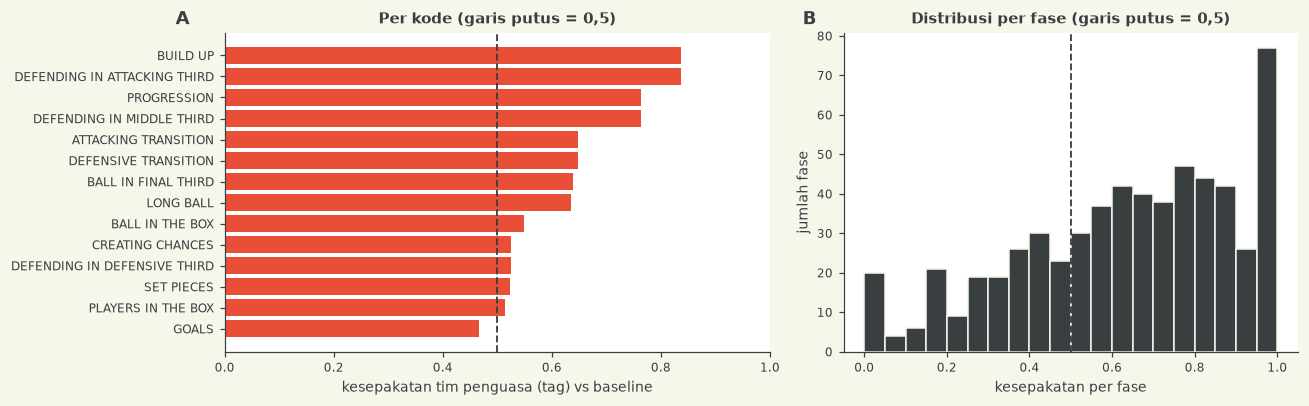

In [11]:
from baseline import smooth
codes_all = common.cached("atd_nearest", lambda: None)
lab50 = smooth(codes_all, 50)                      # 'H' 'A' 'D' per frame

team_map = {"Barcelona": "H", "Atletic Club": "A"}
flip = {"H": "A", "A": "H"}
DEFENDER_CODES = {"DEFENDING IN ATTACKING THIRD", "DEFENDING IN MIDDLE THIRD", "DEFENDING IN DEFENSIVE THIRD", "DEFENSIVE TRANSITION"}
rows = []
for _, r in tags[tags.Team.isin(team_map)].iterrows():
    seg = lab50[r.start_frame:r.end_frame]
    alive = seg[(seg == "H") | (seg == "A")]
    tg = team_map[r.Team]
    pos = flip[tg] if r.code in DEFENDER_CODES else tg          # tim yang diduga menguasai bola
    rows.append({"code": r.code, "alive": len(alive) / max(len(seg), 1),
                 "agree_raw": (alive == tg).mean() if len(alive) else np.nan,
                 "agree": (alive == pos).mean() if len(alive) else np.nan})
ag = pd.DataFrame(rows)
res = ag.groupby("code").agg(n=("agree", "size"), agree_raw=("agree_raw", "mean"), agree=("agree", "mean"), alive=("alive", "mean")).sort_values("agree")
display(res.round(2))
print(f"kesepakatan mentah (Team apa adanya): {ag.agree_raw.mean():.1%} | setelah membalik kode defending: {ag.agree.mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.2, 1]))
ax[0].barh(res.index, res.agree, color=C1); ax[0].axvline(0.5, color=WARM, ls="--", lw=1.2)
ax[0].set(xlim=(0, 1), xlabel="kesepakatan tim penguasa (tag) vs baseline", title="Per kode (garis putus = 0,5)")
ax[1].hist(ag.agree.dropna(), bins=20, color=C2, edgecolor=C3); ax[1].axvline(0.5, color=WARM, ls="--", lw=1.2)
ax[1].set(xlabel="kesepakatan per fase", ylabel="jumlah fase", title="Distribusi per fase (garis putus = 0,5)")
panel(ax[0], "A"); panel(ax[1], "B"); fig.tight_layout(); plt.show()
pass

Membaca `Team` apa adanya hanya cocok 53,7% dengan baseline (hampir kebetulan), karena kode "defending" menamai pihak yang bertahan (kesepakatan mentah 16 sampai 35%). Setelah dibalik, kesepakatan naik menjadi 63,4% secara keseluruhan: `DEFENDING IN ATTACKING THIRD` 84% (sama dengan `BUILD UP`), `DEFENDING IN MIDDLE THIRD` 76% (sama dengan `PROGRESSION`), `DEFENSIVE TRANSITION` 65%. Kode `GOALS`, `SET PIECES`, `PLAYERS IN THE BOX`, `CREATING CHANCES`, dan `DEFENDING IN DEFENSIVE THIRD` tetap sekitar 50%: fase pendek atau bola mati, ketika baseline memang paling lemah. Tag adalah prior yang kuat untuk fase mengalir (`BUILD UP`, `PROGRESSION`) **jika** semantik `Team` per kode ditangani benar, dan tidak berguna untuk lemparan ke dalam (`N/A`).

## [9] Korelasi antar fitur kandidat

Matriks korelasi Spearman antar fitur geometri pada frame yang bolanya terlihat. Fitur yang berkorelasi tinggi memberi informasi redundan; fitur yang hampir independen layak digabung.

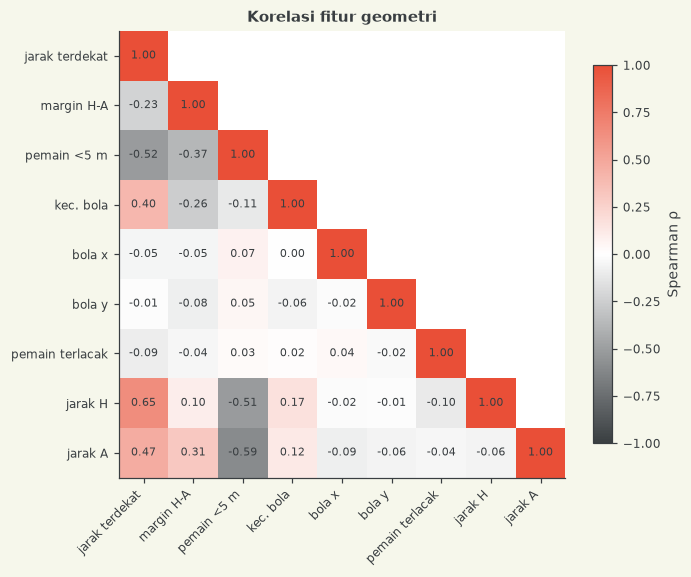

In [12]:
feat = pd.DataFrame({
    "jarak terdekat": near, "margin H-A": margin, "pemain <5 m": within5,
    "kec. bola": ball_speed, "bola x": BX[idx], "bola y": BY[idx],
    "pemain terlacak": NPLAY[idx], "jarak H": np.where(np.isfinite(dh), dh, np.nan),
    "jarak A": np.where(np.isfinite(da), da, np.nan),
}).replace([np.inf, -np.inf], np.nan)
corr = feat.corr(method="spearman")

fig, ax = plt.subplots(figsize=(6.4, 5.4))
mask = np.triu(np.ones_like(corr, bool), 1)
im = ax.imshow(np.ma.array(corr.values, mask=mask), cmap=CMAP_DIV, vmin=-1, vmax=1)
ax.set(xticks=range(len(corr)), yticks=range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right"); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(i + 1):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7, color=INK)
ax.grid(False); plt.colorbar(im, ax=ax, shrink=0.8, label="Spearman ρ")
ax.set_title("Korelasi fitur geometri"); fig.tight_layout(); plt.show()

Jarak terdekat berkorelasi positif dengan jarak H (0,65) dan jarak A (0,47), dan negatif dengan kerumunan dalam 5 m (−0,52), jadi ketiganya sebagian redundan. Kecepatan bola (dihitung dari posisi) berkorelasi sedang dengan jarak terdekat (0,40): bola yang bergerak cepat cenderung jauh dari semua pemain. Posisi bola (x, y) dan jumlah pemain terlacak hampir independen dari geometri lokal (|ρ| < 0,1), sehingga membawa informasi yang berbeda.

## [10] Ground truth publik: pemeriksaan pipeline

Bagian ini **hanya** memastikan frame sejajar dan label bermakna seperti yang dikira. Tidak ada ambang atau aturan yang diambil darinya.

frame dinilai 7500 (11185-18684) | possession 17 | durasi rata-rata 14.2 dtk
H    3454
A    2577
D    1469


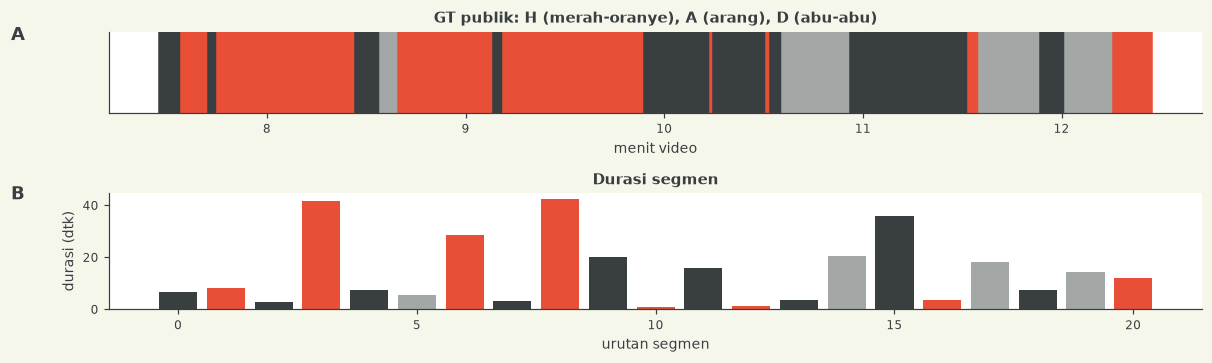

In [13]:
import possession_metrics as pm
gt = pm.read_label_csv(ROOT / "evaluation" / "gt" / "BAR-ATH_possession_gt_public.csv")
lab = gt["label"].astype(str).values
sc = np.flatnonzero(lab != "X")
seg = pd.Series(lab[sc], index=sc)
run = (seg != seg.shift()).cumsum()
sp = seg.groupby(run).agg(label="first", n="size", start=lambda s: s.index[0])
sp["dur"] = sp.n / FPS
poss = sp[sp.label.isin(["H", "A"])]
print(f"frame dinilai {len(sc)} ({sc.min()}-{sc.max()}) | possession {len(poss)} | durasi rata-rata {poss.dur.mean():.1f} dtk")
print(seg.value_counts().to_string())

fig, ax = plt.subplots(2, 1, figsize=(11, 3.4), gridspec_kw=dict(height_ratios=[0.7, 1]))
for _, r in sp.iterrows():
    ax[0].axvspan(r.start / FPS / 60, (r.start + r.n) / FPS / 60, color=TEAM[r.label])
ax[0].set(yticks=[], xlabel="menit video", title="GT publik: H (merah-oranye), A (arang), D (abu-abu)"); ax[0].grid(False)
ax[1].bar(range(len(sp)), sp.dur, color=[TEAM[l] for l in sp.label]); ax[1].set(xlabel="urutan segmen", ylabel="durasi (dtk)", title="Durasi segmen")
panel(ax[0], "A"); panel(ax[1], "B"); fig.tight_layout(); plt.show()

Hanya 17 possession dalam 5 menit: terlalu sedikit untuk memilih antar model (satu possession meleset menggeser spellF1 sekitar enam poin), cukup untuk memeriksa bahwa pipeline benar.

## [11] Homografi dan broadcast

Homografi tactical valid pada semua frame, tetapi berkasnya belum diunduh. Untuk gambaran awal, homografi broadcast tersedia: sebagian frame tidak valid (replay, close-up, penonton).

broadcast: 164488 frame | valid 65.8% | stretch tak valid 123 | terpanjang 109 dtk


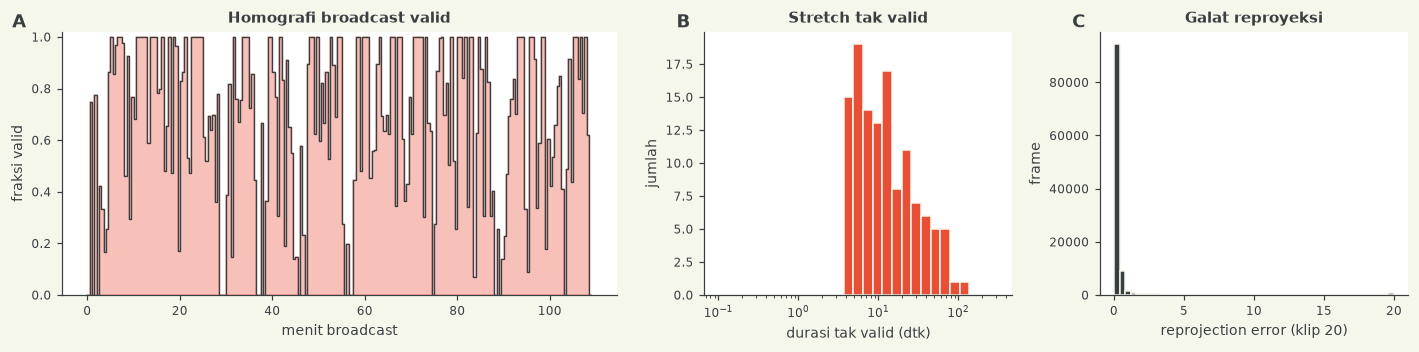

In [14]:
hp = asset_paths(source="broadcast")["homography"]
hb = pd.read_csv(hp, usecols=["frame", "reprojection_error", "valid"])
v = hb.valid.values.astype(bool)
e = np.diff(np.concatenate(([1], v.astype(int), [1])))
inval = (np.flatnonzero(e == 1) - np.flatnonzero(e == -1)) / FPS
print(f"broadcast: {len(hb)} frame | valid {v.mean():.1%} | stretch tak valid {len(inval)} | terpanjang {inval.max():.0f} dtk")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.3), gridspec_kw=dict(width_ratios=[1.8, 1, 1]))
bm = np.arange(len(hb)) / FPS / 60
w = 750
vw = v[:len(v) // w * w].reshape(-1, w).mean(1)
ax[0].fill_between(np.arange(len(vw)) * w / FPS / 60, vw, step="post", color=C1, alpha=0.35); ax[0].plot(np.arange(len(vw)) * w / FPS / 60, vw, color=C2, lw=0.9, drawstyle="steps-post")
ax[0].set(ylim=(0, 1.02), xlabel="menit broadcast", ylabel="fraksi valid", title="Homografi broadcast valid")
ax[1].hist(inval, bins=np.logspace(-1, 2.5, 30), color=C1, edgecolor=C3); ax[1].set(xscale="log", xlabel="durasi tak valid (dtk)", ylabel="jumlah", title="Stretch tak valid")
re = hb.reprojection_error.values[v]; ax[2].hist(np.clip(re, 0, 20), bins=50, color=C2, edgecolor=C3)
ax[2].set(xlabel="reprojection error (klip 20)", ylabel="frame", title="Galat reproyeksi")
for a, l in zip(ax, "ABC"): panel(a, l)
fig.tight_layout(); plt.show()

Broadcast kehilangan sepertiga frame untuk homografi, dan timeline-nya tidak sejajar dengan tactical. Mengingat biaya penyelarasan, broadcast sebaiknya diperlakukan sebagai sumber opsional, bukan fondasi.

# Ringkasan EDA

Temuan utama, semuanya dihitung pada ATD dan Smart Tagging tanpa memakai ground truth untuk tuning:

1. **Skala evaluasi.** Hanya 158.857 dari 199.319 frame dinilai (dua babak); sisanya `X` gratis. Ground truth publik hanya 17 possession, cukup untuk memeriksa pipeline dan tidak untuk memilih model.
2. **Bola hilang adalah keadaan, bukan derau.** Bola terlihat pada 59,3% frame dinilai. Ada 150 gap dengan median 10,7 detik; hanya 11% di bawah 1 detik, dan 85% dari seluruh frame tanpa bola berada di gap lebih dari 10 detik. Interpolasi atau menahan state sebelumnya tidak cukup, state model harus memakai sumber lain selama gap.
3. **Track pemain cukup bersih untuk fitur kolektif.** Rata-rata 20,5 pemain terlacak, tracklet bermedian 13,6 detik dengan ekor panjang, loncatan mustahil hanya sekitar 0,5 per 1000 frame. Slot bukan pemain, jadi fitur per tim lebih aman.
4. **Geometri lokal ambigu pada sepertiga frame.** Pemain terdekat berjarak median 1,9 m, tetapi 32,5% frame berselisih kurang dari 2 m antara pemain terdekat kedua tim. Di sana keputusan per frame lemah dan bukti temporal diperlukan.
5. **Arah serang tertukar per babak** (gawang tuan rumah kiri di babak 1, kanan di babak 2), sehingga fitur posisi harus dinormalkan per babak.
6. **Smart Tagging berguna tetapi punya jebakan semantik.** Ada 142 interval kembar dengan tim berlawanan, dan tag `Team` pada kode "defending" adalah tim yang bertahan. Setelah dibalik, kesepakatan dengan baseline naik dari 53,7% menjadi 63,4% (84% untuk `BUILD UP` / `DEFENDING IN ATTACKING THIRD`). Lemparan ke dalam bertag `N/A`.
7. **Broadcast dan homografi.** Homografi broadcast valid hanya pada 65,8% frame (123 stretch tak valid) dan timeline-nya tidak sejajar, sehingga broadcast tetap opsional. Homografi tactical masih perlu diunduh.

Langkah berikutnya (eksperimen 002): state model temporal berbasis fase (H/A/D) dengan transisi yang mahal, evidens kolektif per tim dari geometri bola-pemain, penahanan state pada gap pendek, prior Smart Tagging dengan semantik `Team` yang benar, dan pencocokan hasil pada metrik possession (bukan per frame).